# Cancer cell-line drug sensitivity and gene-set size

Completed MG-132 study: 50, 200, and 1,000 genes, elastic net and random forest. This notebook loads actual out-of-fold results and checks their integrity. The expensive nested-CV computation is reproducible with the commands below.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
RUN = ROOT/"results/mg132_complete"
design = json.loads((ROOT/"results/study_design/selection.json").read_text())
manifest = json.loads((RUN/"manifest.json").read_text())

## Data provenance and drug selection

The September 2025 CMP TPM archive was joined to October 2023 GDSC2 responses using Sanger model IDs. The selected drug has maximum matched coverage, with ties resolved by numeric ID. This choice was committed before any predictive scores were computed.

In [2]:
display(pd.read_csv(ROOT/"results/study_design/drug_coverage.csv").head(10))
display(pd.Series({k: design[k] for k in ["drug_id", "drug_name", "matched_cell_lines", "selection_rule"]}))
display(pd.Series(design["expression_preparation"]))

,drug_id,matched_cell_lines,DRUG_NAME
0,1862,944,MG-132
1,1003,943,Camptothecin
2,1034,943,Staurosporine
3,1047,943,Nutlin-3a (-)
4,1053,943,MK-2206
5,1054,943,Palbociclib
6,1060,943,PD0325901
7,1073,943,5-Fluorouracil
8,1007,942,Docetaxel
9,1011,942,Navitoclax


drug_id                                                            1862
drug_name                                                        MG-132
matched_cell_lines                                                  944
selection_rule        Maximum unique matched cell lines with finite ...
dtype: object

archive_name                                            rnaseq_merged_20250922.zip
archive_sha256                   a7cf0ea9e22770649011f71c7736e828262ccc0cba332b...
models_name                                                model_list_20261013.csv
models_sha256                    5e2868d7c063dfd83b8965cbab60f7531f508996810799...
matrix_member                                  rnaseq_merged_rsem_tpm_20250922.csv
matrix_crc_verified                                                           True
expression_scale                 Supplied CMP log2(TPM+1); no additional transf...
matrix_samples                                                                1783
mapped_samples                                                                1783
unmapped_or_ambiguous_samples                                                    0
genes                                                                        41131
missing_values                                                             5672286
excl

## Reproducing the computation

Install the repository and dependencies, then run these commands from the repository root with the four downloaded files in `data/raw/`. Use new output paths for a new run. The published results are already available; rerunning model training may take substantial time.

```bash
python -m pip install -e ".[notebook]"
python scripts/prepare_cmp.py --archive data/raw/rnaseq_merged_20250922.zip --models data/raw/model_list_20261013.csv --output data/cmp_reproduction
python scripts/select_drug.py --responses data/raw/GDSC2_fitted_dose_response_27Oct23.xlsx --source-xlsx data/raw/GDSC2_fitted_dose_response_27Oct23.xlsx --compounds data/raw/screened_compounds_rel_8.5_inchi.csv --prepared data/cmp_reproduction --output outputs/reproduction/design
python scripts/run_study.py --jobs 2 --prepared data/cmp_reproduction --design outputs/reproduction/design/selection.json --output outputs/reproduction/run
python scripts/report_study.py --prepared data/cmp_reproduction --run outputs/reproduction/run
```

## Protocol

Five shared outer folds, three inner folds, seed 42. Missingness filtering, imputation, variance filtering, Pearson ranking, and scaling are fitted inside training folds. Inner-fold RMSE chooses parameters. Each outer test set remains untouched until prediction.

In [3]:
display(pd.Series(manifest["config"]))
display(pd.DataFrame(manifest["tuning"]))

gene_counts           [50, 200, 1000]
outer_folds                         5
inner_folds                         3
seed                               42
max_missing                       0.2
n_jobs                              2
trees                             200
cache_dir      outputs/training_cache
dtype: object

,fold,model,gene_count,inner_rmse,params
0,1,elastic_net,50,0.591268,"{'model__alpha': 0.1, 'model__l1_ratio': 0.5}"
1,1,random_forest,50,0.593904,"{'model__max_features': 0.3, 'model__min_sampl..."
2,1,elastic_net,200,0.590493,"{'model__alpha': 0.1, 'model__l1_ratio': 0.1}"
3,1,random_forest,200,0.587934,"{'model__max_features': 0.3, 'model__min_sampl..."
4,1,elastic_net,1000,0.604640,"{'model__alpha': 1.0, 'model__l1_ratio': 0.1}"
5,1,random_forest,1000,0.589137,"{'model__max_features': 1.0, 'model__min_sampl..."
6,2,elastic_net,50,0.694275,"{'model__alpha': 1.0, 'model__l1_ratio': 0.1}"
7,2,random_forest,50,0.640884,"{'model__max_features': 0.3, 'model__min_sampl..."
8,2,elastic_net,200,0.684206,"{'model__alpha': 1.0, 'model__l1_ratio': 0.1}"
9,2,random_forest,200,0.634894,"{'model__max_features': 1.0, 'model__min_sampl..."


## Verify predictions and recompute fold errors

In [4]:
pred = pd.read_csv(RUN/"predictions.csv")
metrics = pd.read_csv(RUN/"fold_metrics.csv")
summary = pd.read_csv(RUN/"summary.csv")
assert len(pred) == 944 * 7
assert not pred.duplicated(["cell_line_id", "model", "gene_count"]).any()
assert (pred.groupby("cell_line_id").fold.nunique() == 1).all()
assert (pred.groupby(["model", "gene_count"]).size() == 944).all()
assert (pred.groupby("cell_line_id")["observed"].nunique() == 1).all()
baseline = pred[pred.model == "mean_baseline"]
for fold, group in baseline.groupby("fold"):
    np.testing.assert_allclose(group.predicted, baseline.loc[baseline.fold != fold, "observed"].mean())
for keys, group in pred.groupby(["fold", "model", "gene_count"]):
    fold, model, k = keys
    reported = metrics[(metrics.fold == fold) & (metrics.model == model) & (metrics.gene_count == k)].iloc[0]
    np.testing.assert_allclose(np.sqrt(np.mean((group.observed-group.predicted)**2)), reported.rmse)
print("Passed: one held-out prediction per configuration and cell line; shared folds; recomputed RMSE.")
display(summary)

Passed: one held-out prediction per configuration and cell line; shared folds; recomputed RMSE.


,model,gene_count,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,elastic_net,50,0.613175,0.090333,0.450783,0.044038,0.206735,0.060300
1,elastic_net,200,0.609846,0.073057,0.445229,0.033193,0.210583,0.070438
2,elastic_net,1000,0.633056,0.098046,0.459241,0.045461,0.155162,0.072545
3,mean_baseline,0,0.698680,0.108585,0.502899,0.052505,-0.025916,0.021570
4,random_forest,50,0.600016,0.088325,0.439769,0.042188,0.240275,0.060066
5,random_forest,200,0.605784,0.088536,0.441164,0.036126,0.226213,0.045774
6,random_forest,1000,0.609980,0.087205,0.445710,0.038251,0.214153,0.058910


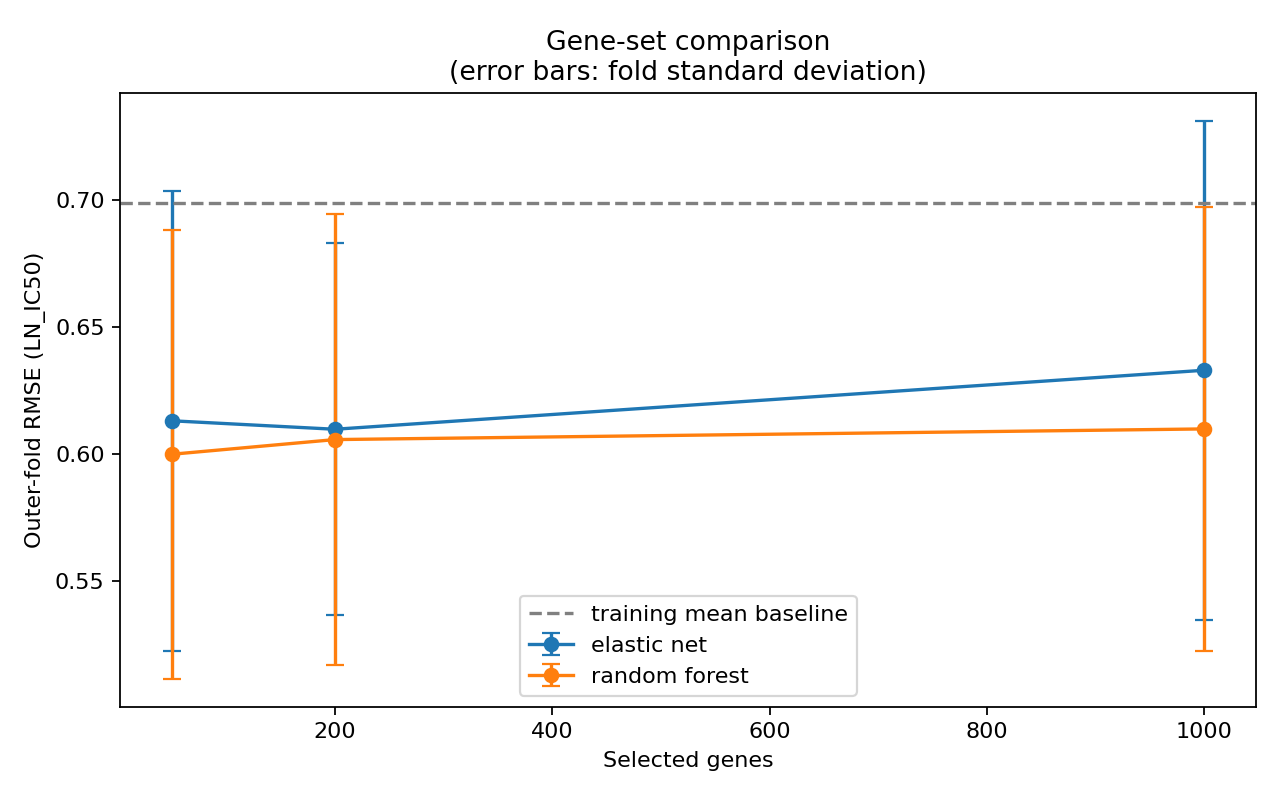

In [5]:
display(Image(filename=str(RUN/"rmse_by_gene_count.png")))

## Paired fold comparisons

Negative RMSE differences favor the larger gene set. Fold standard deviations are descriptive and are not confidence intervals. Similar scores do not prove equivalence.

,model,smaller_genes,larger_genes,mean_rmse_difference,folds_larger_better
0,elastic_net,50,200,-0.003329,1
1,elastic_net,50,1000,0.019880,0
2,elastic_net,200,1000,0.023209,0
3,random_forest,50,200,0.005768,1
4,random_forest,50,1000,0.009963,1
5,random_forest,200,1000,0.004195,1


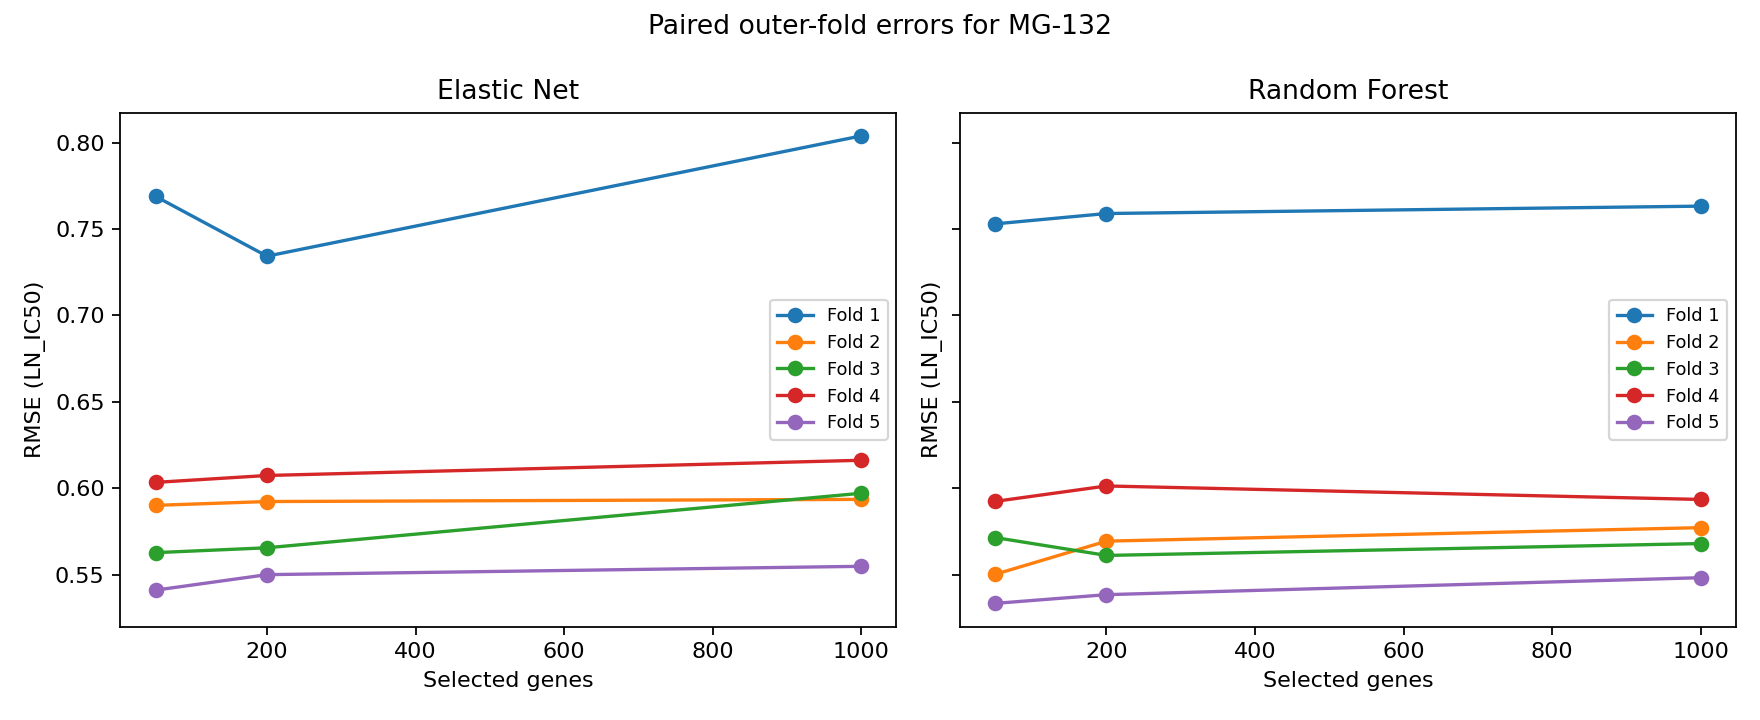

In [6]:
display(pd.read_csv(RUN/"paired_comparison_summary.csv"))
display(Image(filename=str(RUN/"paired_fold_errors.png")))

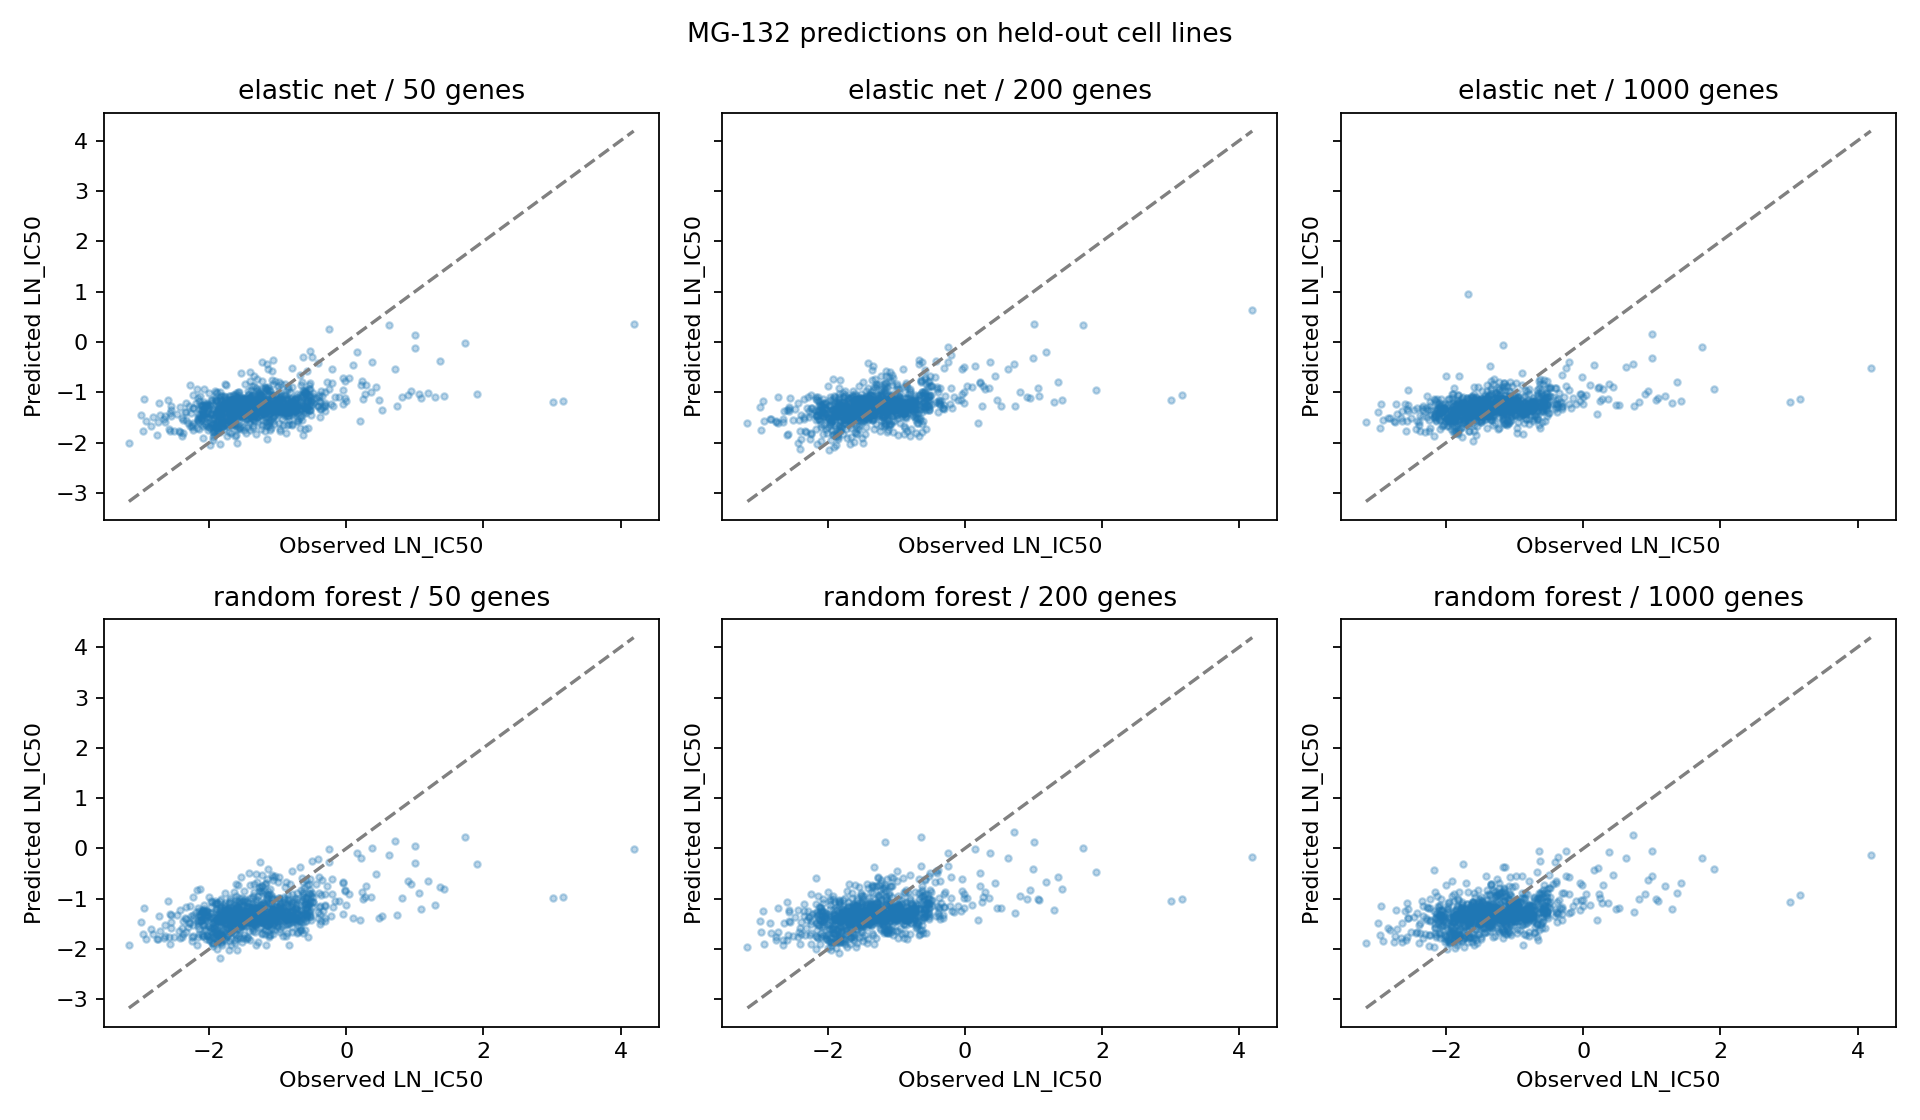

In [7]:
display(Image(filename=str(RUN/"observed_vs_predicted.png")))

## Tissue and expression-source diagnostics

Metadata baselines use only the training-fold group mean, with an overall training-mean fallback. These are supplementary diagnostics, not causal adjustments.

In [8]:
display(pd.read_csv(ROOT/"results/study_design/tissue_composition.csv"))
display(pd.read_csv(ROOT/"results/study_design/expression_sources.csv"))
display(pd.read_csv(RUN/"metadata_baselines.csv").groupby("baseline")[["rmse", "mae", "r2"]].mean())

,tissue,cell_lines,mean_ln_ic50,std_ln_ic50
0,Lung,171,-0.938392,0.775980
1,Haematopoietic and Lymphoid,166,-1.718726,0.536423
2,Skin,57,-1.500984,0.469754
3,Central Nervous System,55,-1.418658,0.537558
4,Breast,51,-1.134063,1.015507
5,Large Intestine,48,-1.312334,0.585734
6,Ovary,41,-1.243491,0.648759
7,Bone,41,-1.292385,0.479116
8,Head and Neck,40,-1.396361,0.441080
9,Esophagus,35,-1.199583,0.484612


,expression_source,cell_lines,mean_ln_ic50
0,Broad,547,-1.253747
1,Sanger,397,-1.345211


,rmse,mae,r2
baseline,,,
expression_source_training_mean,0.697178,0.500637,-0.021225
tissue_training_mean,0.675851,0.482040,0.030581


## Exploratory gene stability

Training folds overlap, so repeated selection is not independent validation. Forest importance has no direction; elastic-net weights apply to standardized expression.

In [9]:
display(pd.read_csv(RUN/"top_genes_50.csv")[["model", "gene_symbol", "gene", "fold_count", "mean_abs_weight_when_selected"]])

,model,gene_symbol,gene,fold_count,mean_abs_weight_when_selected
0,elastic_net,KRT8P43,ENSG00000218186,5,0.071561
1,elastic_net,AKR1B10P1,ENSG00000213606,5,0.064989
2,elastic_net,RPL18A,ENSG00000105640,5,0.042739
3,elastic_net,CUEDC1,ENSG00000180891,5,0.035502
4,elastic_net,FAM177A1,ENSG00000151327,5,0.022232
5,elastic_net,KRT8,ENSG00000170421,5,0.015032
6,elastic_net,CYP4F3,ENSG00000186529,5,0.014130
7,elastic_net,IL12RB1,ENSG00000096996,5,0.013918
8,elastic_net,KBTBD8,ENSG00000163376,5,0.011021
9,elastic_net,TSKU,ENSG00000182704,5,0.004908


## Interpretation and limits

Read [the study report](../results/mg132_complete/report.md) and [biological interpretation](../results/mg132_complete/biology.md). This is one-drug internal cell-line evaluation with mixed expression sources and random tissue-mixed folds. It provides no external or clinical validation. The best observed configuration is selected from the same evaluation comparison and should not be described as an independently established winner.